# Control
*One servo joint under many gains: settling time, overshoot and a tuned controller*

A controller moves a servo joint to a new angle. Two gains decide how: a stiff, lightly damped choice overshoots and rings, a soft one crawls. This page runs the same plant under a grid of gain pairs at once, stops each lane as soon as its response has settled, and then tunes the gains by following the gradient of a cost, in reverse mode, from forty starting points at once.

**Time:** ~5 min &middot; **Runs on:** CPU (same code on GPU) &middot;
**You need:** hawk, eagle, NumPy and matplotlib; read first: [hawk in your domain](../vocabulary)

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "hawk"
    for rel in (
        "docs/content/_shared/anim.py",
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/hawk/{ref}/{rel}", root / rel)
    (root / "docs/content/vocabulary").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/vocabulary")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "_shared"))
from nb_helpers import gpu_available, on_device, plot_style, show, to_numpy, xp
plot_style()

## The plant, once

A joint with inertia `J` and a little viscous friction `b`, driven by a PD controller that is asked to move it from angle 0 to angle 1 (a unit step): `J theta'' = Kp (1 - theta) - Kd theta' - b theta'`. Write `e = 1 - theta` for the error and `v = theta'` for the rate, so `e' = -v` and `v' = (Kp e - (Kd + b) v) / J`.

- `Kp` is the proportional gain and `Kd` the derivative gain; the rest, `J = 1` and `b = 0.1`, are the plant. With `c = Kd + b`, the response has natural frequency `omega = sqrt(Kp / J)` and damping ratio `zeta = c / (2 sqrt(Kp J))`.
- The model leaves out actuator limits, sensor noise, delay and joint stiction: it is the textbook loop, with the textbook closed forms.
- **Settled** means the energy of the error, `E = (1/2) Kp e^2 + (1/2) J v^2`, has fallen below that of a 2% offset, `(1/2) Kp 0.02^2`. The energy only ever falls (`E' = -c v^2`), so a settled response never leaves the 2% band again. That makes it a guaranteed version of the usual settling time, never earlier than the last exit from the band.

Declare the words as a `KernelKind` once: the two gains per lane and the plant as parameters.

In [3]:
import numpy as np
import eagle
import hawk
import hawk.math as m
from hawk import Grid, Mutable, Param, Scalar
from hawk.ext import DATA_ONLY, KernelKind


class Plant(KernelKind, slug="plant"):
    kp: Scalar          # proportional gain, one per lane
    kd: Scalar          # derivative gain, one per lane
    inertia: Param      # J (kg m^2)
    friction: Param     # b (N m s / rad)
    guard = DATA_ONLY

Plant

__main__.Plant

## One lane per gain pair, and a stop

The lane space is the plane of gains: `Grid["gain_p", "gain_d":N]`, one lane per pair of `Kp` and `Kd`. The kernel steps the response with RK4 and leaves its loop at the step where the energy crosses the threshold, interpolating the crossing inside the step. It also keeps the peak overshoot.

`if e_now < e_tol: t_settle = ...; break` is the stop: a lane that has settled does no more work. A lane that never settles keeps `t_settle` at the horizon.

The two gain axes come from two short arrays; NumPy's broadcasting does the rest. `kp = kps[:, None]` and `kd = kds[None, :]` bind as they are, without being expanded to the whole grid, and the kernel reads each along the axis it varies on. The step `dt` and the horizon are part of the kernel, so a small function builds it.

In [4]:
DT, HORIZON, N_GAINS = 0.01, 30.0, 48
INERTIA, FRICTION, BAND = 1.0, 0.1, 0.02


def make_settle(dt, horizon, n_kd):
    steps = round(horizon / dt)

    @Plant
    def settle(lane: Grid["gain_p", "gain_d":n_kd], kp, kd, inertia, friction, band: Param,
               t_settle: Mutable[Scalar], overshoot: Mutable[Scalar]):
        c = kd + friction
        e = 1.0
        v = 0.0
        energy = 0.5 * kp
        e_tol = 0.5 * kp * band * band
        peak = 0.0
        t_settle = horizon                                              # a lane that never settles keeps the horizon
        for k in range(steps):
            k1e = -v
            k1v = (kp * e - c * v) / inertia
            k2e = -(v + 0.5 * dt * k1v)
            k2v = (kp * (e + 0.5 * dt * k1e) - c * (v + 0.5 * dt * k1v)) / inertia
            k3e = -(v + 0.5 * dt * k2v)
            k3v = (kp * (e + 0.5 * dt * k2e) - c * (v + 0.5 * dt * k2v)) / inertia
            k4e = -(v + dt * k3v)
            k4v = (kp * (e + dt * k3e) - c * (v + dt * k3v)) / inertia
            e = e + dt * (k1e + 2.0 * k2e + 2.0 * k3e + k4e) / 6.0
            v = v + dt * (k1v + 2.0 * k2v + 2.0 * k3v + k4v) / 6.0
            e_now = 0.5 * kp * e * e + 0.5 * inertia * v * v
            peak = m.max(peak, -e)
            if e_now < e_tol:                                           # settled: the crossing, interpolated in the step
                t_settle = (k + (energy - e_tol) / (energy - e_now)) * dt
                break
            energy = e_now
        overshoot = peak
    return settle


kps = np.geomspace(0.5, 40.0, N_GAINS)                          # Kp, N m / rad
kds = np.geomspace(0.2, 12.0, N_GAINS)                          # Kd, N m s / rad
settle = make_settle(DT, HORIZON, N_GAINS)
grid = settle(kp=kps[:, None], kd=kds[None, :], inertia=INERTIA, friction=FRICTION, band=BAND, gain_p=N_GAINS)
t_settle, overshoot = np.asarray(grid["t_settle"]), np.asarray(grid["overshoot"])
i, j = np.unravel_index(t_settle.argmin(), t_settle.shape)
print(f"{t_settle.size} gain pairs in one call; {(t_settle >= HORIZON).sum()} never settle within {HORIZON:g} s")
print(f"fastest: Kp = {kps[i]:.2f}, Kd = {kds[j]:.2f} settles in {t_settle[i, j]:.2f} s with {overshoot[i, j] * 100:.1f}% overshoot")

2304 gain pairs in one call; 94 never settle within 30 s
fastest: Kp = 40.00, Kd = 10.08 settles in 0.72 s with 0.9% overshoot


## Check it against what is known

The loop is linear, so every number has a closed form, and the checks use only that.

**Settling time.** The exact response of `e'' + (c / J) e' + (Kp / J) e = 0` from `e = 1`, `v = 0` is a damped cosine and sine when `zeta < 1` and two exponentials when `zeta > 1`. The exact energy follows from it, and bisection on the exact energy finds when it crosses the threshold. The kernel must agree on every settled lane of the grid. Its error comes from the interpolation inside the step, so it should fall by about 4 when `dt` is halved, which is second order; the RK4 steps are not the limit.

**Overshoot.** For `zeta < 1` the peak overshoot is `exp(-pi zeta / sqrt(1 - zeta^2))`. The kernel samples the peak on its time grid, so it sits just under the exact value, and a lane whose energy is under the threshold before its first peak, an overshoot inside the 2% band, has settled and records none; the check uses the lanes whose overshoot is above twice the band.

**Stability, against the Jacobian.** The loop's Jacobian is the 2 x 2 matrix `[[0, -1], [Kp / J, -c / J]]`. RK4 is stable on the negative real axis while `dt` times the largest eigenvalue in size stays below 2.785. The check takes the eigenvalues of the grid's corners and counts them against it.

In [5]:
def exact_energy(t, kp, c, J=INERTIA):
    # (1/2) kp e^2 + (1/2) J v^2 of the exact response from e = 1, v = 0; arrays broadcast
    s = np.sqrt(np.complex128(c**2 / J**2 - 4 * kp / J))             # roots of s^2 + (c/J) s + kp/J = 0 are (-c/J +- s) / 2
    l1, l2 = (-c / J + s) / 2, (-c / J - s) / 2
    e = ((l2 * np.exp(l1 * t) - l1 * np.exp(l2 * t)) / (l2 - l1)).real
    de = ((l1 * l2) * (np.exp(l1 * t) - np.exp(l2 * t)) / (l2 - l1)).real           # e' = -v
    return 0.5 * kp * e**2 + 0.5 * J * de**2


def exact_settle(kp, kd, band=BAND, hi=60.0):
    # bisection on the exact, monotone energy: the first time it is below that of a `band` offset
    kp, kd = np.broadcast_arrays(kp, kd)
    c = kd + FRICTION
    lo, up = np.zeros(kp.shape), np.full(kp.shape, hi)
    for _ in range(70):
        mid = 0.5 * (lo + up)
        below = exact_energy(mid, kp, c) < 0.5 * kp * band**2
        up, lo = np.where(below, mid, up), np.where(below, lo, mid)
    return 0.5 * (lo + up)


def settle_error(dt):
    ks = np.geomspace(1.0, 20.0, 12); ds = np.geomspace(0.5, 8.0, 12)
    got = np.asarray(make_settle(dt, HORIZON, 12)(kp=ks[:, None], kd=ds[None, :], inertia=INERTIA, friction=FRICTION, band=BAND, gain_p=12)["t_settle"])
    return np.abs(got - exact_settle(ks[:, None], ds[None, :]))[got < HORIZON].max()          # lanes that settle within the horizon


errors = [settle_error(dt) for dt in (0.04, 0.02, 0.01)]
for dt, err in zip((0.04, 0.02, 0.01), errors):
    print(f"dt = {dt}: worst settling-time error {err:.1e} s")
order = [errors[0] / errors[1], errors[1] / errors[2]]
assert all(3.0 < r < 5.5 for r in order), order
print(f"halving dt divides the error by {order[0]:.1f} and {order[1]:.1f}: second order (the interpolation in the step)")

reference = exact_settle(kps[:, None], kds[None, :])
ok = t_settle < HORIZON
TOL_SETTLE = 2e-3
gap = np.abs(t_settle - reference)[ok].max()
assert gap < TOL_SETTLE, gap
print(f"settling time against the exact response on {ok.sum()} settled lanes: worst gap {gap:.1e} s < {TOL_SETTLE:g} s (dt = {DT})")

zeta = (kds[None, :] + FRICTION) / (2 * np.sqrt(kps[:, None] * INERTIA))
under = (zeta < 0.9) & (zeta > 0.1)
visible = np.exp(-np.pi * zeta / np.sqrt(1 - np.minimum(zeta, 0.99) ** 2)) > 2 * BAND           # a peak above the band comes before the settling
exact_over = np.exp(-np.pi * zeta / np.sqrt(1 - np.minimum(zeta, 0.99) ** 2))
gap_over = np.abs(overshoot - exact_over)[under & ok & visible].max()
assert gap_over < 2e-3, gap_over
print(f"overshoot against exp(-pi zeta / sqrt(1 - zeta^2)) on {(under & ok & visible).sum()} underdamped lanes with an overshoot above the band: worst gap {gap_over:.1e}")

LIMIT = 2.785
worst = max(np.abs(np.linalg.eigvals(np.array([[0.0, -1.0], [kp / INERTIA, -(kd + FRICTION) / INERTIA]]))).max()
            for kp in (kps[0], kps[-1]) for kd in (kds[0], kds[-1]))
print(f"largest |eigenvalue| at the grid corners {worst:.1f} per s; dt x that = {DT * worst:.3f} (limit {LIMIT})")
assert DT * worst < LIMIT

dt = 0.04: worst settling-time error 2.8e-03 s
dt = 0.02: worst settling-time error 8.7e-04 s
dt = 0.01: worst settling-time error 1.9e-04 s
halving dt divides the error by 3.3 and 4.5: second order (the interpolation in the step)


settling time against the exact response on 2210 settled lanes: worst gap 6.6e-04 s < 0.002 s (dt = 0.01)
overshoot against exp(-pi zeta / sqrt(1 - zeta^2)) on 1145 underdamped lanes with an overshoot above the band: worst gap 3.0e-04
largest |eigenvalue| at the grid corners 12.1 per s; dt x that = 0.121 (limit 2.785)


## A conserved quantity: the energy balance

The model loses energy at the rate `c v^2` and at no other: `E(0) - E(T) = integral of c v^2 dt`. A second kernel, `plant_cost`, integrates this next to the response, for a fixed horizon `T = 15 s` and no stop. It also integrates the cost the tuning below will minimise, `integral of (e^2 + w u^2) dt`, the squared error plus `w = 0.01` times the squared control `u = Kp e - Kd v`. Both are extra states in the same RK4 step. The balance holds to the scheme's error, which is the check that the integration and the model agree; it does not hold by construction.

In [6]:
T_COST, W_EFFORT = 15.0, 0.01


def make_cost(dt, horizon):
    steps = round(horizon / dt)

    @Plant
    def plant_cost(kp, kd, inertia, friction, w: Param, cost: Mutable[Scalar], lost: Mutable[Scalar], e_end: Mutable[Scalar]):
        c = kd + friction
        e = 1.0
        v = 0.0
        q = 0.0                                                         # the cost so far
        d = 0.0                                                         # the energy dissipated so far
        for _ in range(steps):
            k1e = -v
            k1v = (kp * e - c * v) / inertia
            k1q = e * e + w * (kp * e - kd * v) * (kp * e - kd * v)
            k1d = c * v * v
            e2 = e + 0.5 * dt * k1e
            v2 = v + 0.5 * dt * k1v
            k2e = -v2
            k2v = (kp * e2 - c * v2) / inertia
            k2q = e2 * e2 + w * (kp * e2 - kd * v2) * (kp * e2 - kd * v2)
            k2d = c * v2 * v2
            e3 = e + 0.5 * dt * k2e
            v3 = v + 0.5 * dt * k2v
            k3e = -v3
            k3v = (kp * e3 - c * v3) / inertia
            k3q = e3 * e3 + w * (kp * e3 - kd * v3) * (kp * e3 - kd * v3)
            k3d = c * v3 * v3
            e4 = e + dt * k3e
            v4 = v + dt * k3v
            k4e = -v4
            k4v = (kp * e4 - c * v4) / inertia
            k4q = e4 * e4 + w * (kp * e4 - kd * v4) * (kp * e4 - kd * v4)
            k4d = c * v4 * v4
            e = e + dt * (k1e + 2.0 * k2e + 2.0 * k3e + k4e) / 6.0
            v = v + dt * (k1v + 2.0 * k2v + 2.0 * k3v + k4v) / 6.0
            q = q + dt * (k1q + 2.0 * k2q + 2.0 * k3q + k4q) / 6.0
            d = d + dt * (k1d + 2.0 * k2d + 2.0 * k3d + k4d) / 6.0
        cost = q
        lost = d
        e_end = 0.5 * kp * e * e + 0.5 * inertia * v * v
    return plant_cost


plant_cost = make_cost(DT, T_COST)
pair_kp, pair_kd = np.array([1.0, 3.0, 8.0, 20.0]), np.array([0.5, 2.0, 4.0, 6.0])
bal = plant_cost(kp=pair_kp, kd=pair_kd, inertia=INERTIA, friction=FRICTION, w=W_EFFORT)
balance = (np.abs(0.5 * pair_kp - np.asarray(bal["e_end"]) - np.asarray(bal["lost"])) / (0.5 * pair_kp)).max()
TOL_BALANCE = 1e-6
assert balance < TOL_BALANCE, balance
print(f"energy balance E(0) - E(T) = integral of c v^2 dt on four gain pairs: worst gap {balance:.1e} of E(0) (< {TOL_BALANCE:g})")

energy balance E(0) - E(T) = integral of c v^2 dt on four gain pairs: worst gap 2.4e-07 of E(0) (< 1e-06)


## The gradient the tuning needs

`hawk.diff.vjp(plant_cost, wrt=("kp", "kd"))` derives the reverse-mode kernel, and `eagle.deploy` takes the kernel and its derivative together. With a seed of one on `cost`, every lane returns `d cost / d Kp` and `d cost / d Kd` for its own gain pair, so a whole population of gain pairs gets its gradients in one launch.

Two checks, on a ring of gain pairs around the best the grid found.
- **Exactness:** a central finite difference of the same integration, float64, relative step 1e-6. It is the derivative of exactly what the kernel computes, so the tolerance is a rounding one.
- **Closed form:** the cost of the loop is also `x0^T P x0`, where `P` solves the Lyapunov equation `A^T P + P A = -Q`, with `x0 = (1, 0)` and `Q` built from `e^2 + w u^2`. That is the cost to infinite time, from a 3 x 3 linear solve; differencing it gives a derivative with no integration step in it. It differs from the kernel's by the scheme's error and the part of the cost after 15 s, which at these gains is far below the tolerance.

In [7]:
from hawk import Kernel
from hawk.diff import vjp

cost_vjp = Kernel("plant_cost_vjp", vjp(plant_cost, wrt=("kp", "kd")))
cost_run, cost_grad = eagle.deploy([plant_cost, cost_vjp])


def cost_and_grad(kp, kd):
    # cost, d cost / d kp and d cost / d kd for every gain pair: one forward and one reverse launch
    n = len(kp)
    z = np.zeros(n)
    f = cost_run.run(kp=kp, kd=kd, inertia=INERTIA, friction=FRICTION, w=W_EFFORT)["cost"]
    g = cost_grad.run(kp=kp, kd=kd, inertia=INERTIA, friction=FRICTION, w=W_EFFORT, bar_cost=np.ones(n), bar_lost=z, bar_e_end=z)
    return np.asarray(f), np.asarray(g["bar_kp"]), np.asarray(g["bar_kd"])


def closed_cost(kp, kd, w=W_EFFORT):
    # x0^T P x0, with A^T P + P A = -Q, to infinite time; x = (e, v)
    kp, kd = np.broadcast_arrays(np.asarray(kp, dtype=float), np.asarray(kd, dtype=float))
    a12, a21, a22 = -1.0, kp / INERTIA, -(kd + FRICTION) / INERTIA
    q11, q12, q22 = 1.0 + w * kp**2, -w * kp * kd, w * kd**2
    M = np.zeros(kp.shape + (3, 3))
    M[..., 0, 0], M[..., 0, 1] = 0.0, 2 * a21                      # row for p11: 2 (a11 p11 + a21 p12), a11 = 0
    M[..., 1, 0], M[..., 1, 1], M[..., 1, 2] = a12, a22, a21        # row for p12: a12 p11 + (a11 + a22) p12 + a21 p22
    M[..., 2, 1], M[..., 2, 2] = 2 * a12, 2 * a22                  # row for p22: 2 (a12 p12 + a22 p22)
    rhs = -np.stack([q11, q12, q22], axis=-1)
    return np.linalg.solve(M, rhs[..., None])[..., 0][..., 0]


ring_kp = np.array([2.0, 3.0, 5.0, 8.0, 3.0, 5.0, 8.0, 5.0])
ring_kd = np.array([1.5, 2.5, 3.5, 4.5, 4.5, 2.0, 3.0, 5.0])
f0, gp, gd = cost_and_grad(ring_kp, ring_kd)

rel = 1e-6
fd_p = (cost_and_grad(ring_kp * (1 + rel), ring_kd)[0] - cost_and_grad(ring_kp * (1 - rel), ring_kd)[0]) / (2 * rel * ring_kp)
fd_d = (cost_and_grad(ring_kp, ring_kd * (1 + rel))[0] - cost_and_grad(ring_kp, ring_kd * (1 - rel))[0]) / (2 * rel * ring_kd)
TOL_GRAD = 1e-6
gap = max(np.abs(gp - fd_p).max() / np.abs(gp).max(), np.abs(gd - fd_d).max() / np.abs(gd).max())
assert gap < TOL_GRAD, gap
print(f"gradient against central differences on {2 * len(ring_kp)} derivatives: worst gap {gap:.1e} of the largest value < {TOL_GRAD:g}")

TOL_COST = 1e-6
assert np.abs(f0 - closed_cost(ring_kp, ring_kd)).max() / f0.max() < TOL_COST
h = 1e-6
cf_p = (closed_cost(ring_kp * (1 + h), ring_kd) - closed_cost(ring_kp * (1 - h), ring_kd)) / (2 * h * ring_kp)
cf_d = (closed_cost(ring_kp, ring_kd * (1 + h)) - closed_cost(ring_kp, ring_kd * (1 - h))) / (2 * h * ring_kd)
gap_cf = max(np.abs(gp - cf_p).max() / np.abs(gp).max(), np.abs(gd - cf_d).max() / np.abs(gd).max())
assert gap_cf < 1e-5, gap_cf
print(f"cost and gradient against the Lyapunov closed form: gap {gap_cf:.1e} of the largest value < 1e-5")

gradient against central differences on 16 derivatives: worst gap 3.8e-09 of the largest value < 1e-06
cost and gradient against the Lyapunov closed form: gap 2.3e-08 of the largest value < 1e-5


## Tune it: forty starts at once

Forty gain pairs, spread over the grid, each follow the gradient of the cost downhill, all in one launch per step. The rule is steepest descent in `ln Kp` and `ln Kd` (both stay positive, and a step means the same for both) with a step length per lane: a step that lowers the cost is accepted and its length grows by 20%; one that does not is refused and the length halves. The loop stops when every length is below 1e-5.

The reference is the closed-form cost on a fine grid of gains, refined around its smallest value. All forty must end at that minimum, to within 1% in each gain. For this loop the linear-quadratic theory also says the best stiffness is exactly `Kp = 1 / sqrt(w)`, which the minimum must reproduce.

In [8]:
rng = np.random.default_rng(5)
n_start = 40
start = np.stack([np.exp(rng.uniform(np.log(0.6), np.log(30.0), n_start)), np.exp(rng.uniform(np.log(0.3), np.log(10.0), n_start))])
x = np.log(start)                                               # (2, start): ln Kp, ln Kd
length = np.full(n_start, 0.3)
f, gp, gd = cost_and_grad(*np.exp(x))
trail = [x.copy()]
for iteration in range(1, 400):
    g = np.stack([gp * np.exp(x[0]), gd * np.exp(x[1])])        # d cost / d ln gain
    step = -g / np.maximum(np.linalg.norm(g, axis=0), 1e-300)
    trial = x + length * step
    f_new, gp_new, gd_new = cost_and_grad(*np.exp(trial))
    better = f_new < f
    x = np.where(better, trial, x)
    f = np.where(better, f_new, f)
    gp, gd = np.where(better, gp_new, gp), np.where(better, gd_new, gd)
    length = np.where(better, length * 1.2, length * 0.5)
    trail.append(x.copy())
    if length.max() < 1e-5:
        break
best = np.exp(x)
print(f"{n_start} starts, {iteration} steps; cost from {cost_and_grad(*start)[0].mean():.2f} (mean) to {f.mean():.4f}")

fine_p, fine_d = np.geomspace(0.5, 40, 400), np.geomspace(0.2, 12, 400)
surface = closed_cost(fine_p[:, None], fine_d[None, :])
a, b = np.unravel_index(surface.argmin(), surface.shape)
for _ in range(4):                                              # refine around the smallest value
    fine_p = np.geomspace(fine_p[max(a - 2, 0)], fine_p[min(a + 2, len(fine_p) - 1)], 201)
    fine_d = np.geomspace(fine_d[max(b - 2, 0)], fine_d[min(b + 2, len(fine_d) - 1)], 201)
    surface = closed_cost(fine_p[:, None], fine_d[None, :])
    a, b = np.unravel_index(surface.argmin(), surface.shape)
opt_p, opt_d = fine_p[a], fine_d[b]
spread = np.abs(best / np.array([[opt_p], [opt_d]]) - 1).max()
assert spread < 0.01, spread
zeta_opt = (opt_d + FRICTION) / (2 * np.sqrt(opt_p * INERTIA))
print(f"closed-form minimum at Kp = {opt_p:.3f}, Kd = {opt_d:.3f}; all {n_start} starts end within {spread * 100:.2f}% of it")
assert abs(opt_p * np.sqrt(W_EFFORT) - 1) < 5e-3, opt_p
print(f"Kp x sqrt(w) = {opt_p * np.sqrt(W_EFFORT):.4f}: the optimal stiffness is 1 / sqrt(w), the linear-quadratic result; the damping ratio is {zeta_opt:.3f}")

40 starts, 73 steps; cost from 1.30 (mean) to 0.4473


closed-form minimum at Kp = 10.000, Kd = 4.373; all 40 starts end within 0.00% of it
Kp x sqrt(w) = 1.0000: the optimal stiffness is 1 / sqrt(w), the linear-quadratic result; the damping ratio is 0.707


## The picture

Left: the settling time of every gain pair of the grid, on a log scale, from the one call above; the white curve is critical damping, `zeta = 1`, and the dots are the forty tuned gains, which all end together at one point on the underdamped side of it. Right: the step response of four gain pairs, computed by a small kernel with one lane per (gain pair, time) and drawn with each one's exact settling time: too soft, too lively, over-damped and the tuned pair.

the four step responses against the exact solution: worst gap 1.8e-05



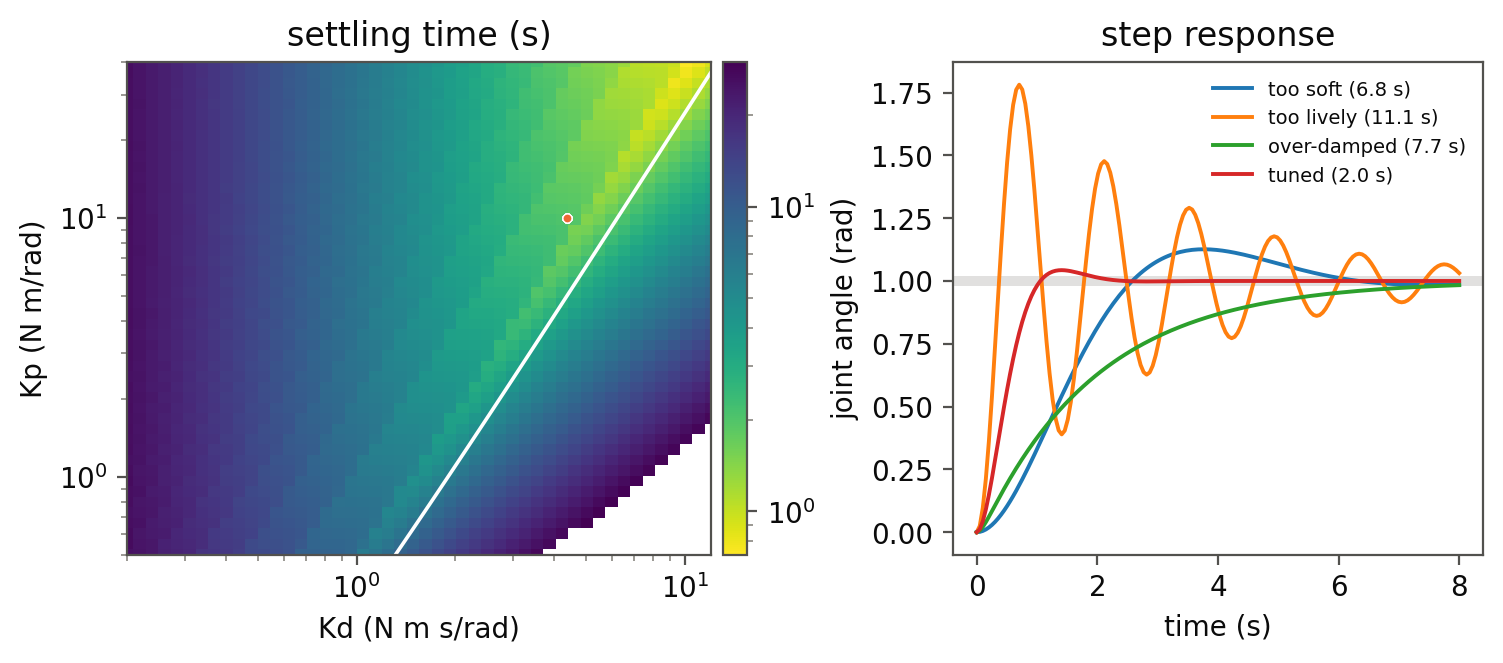
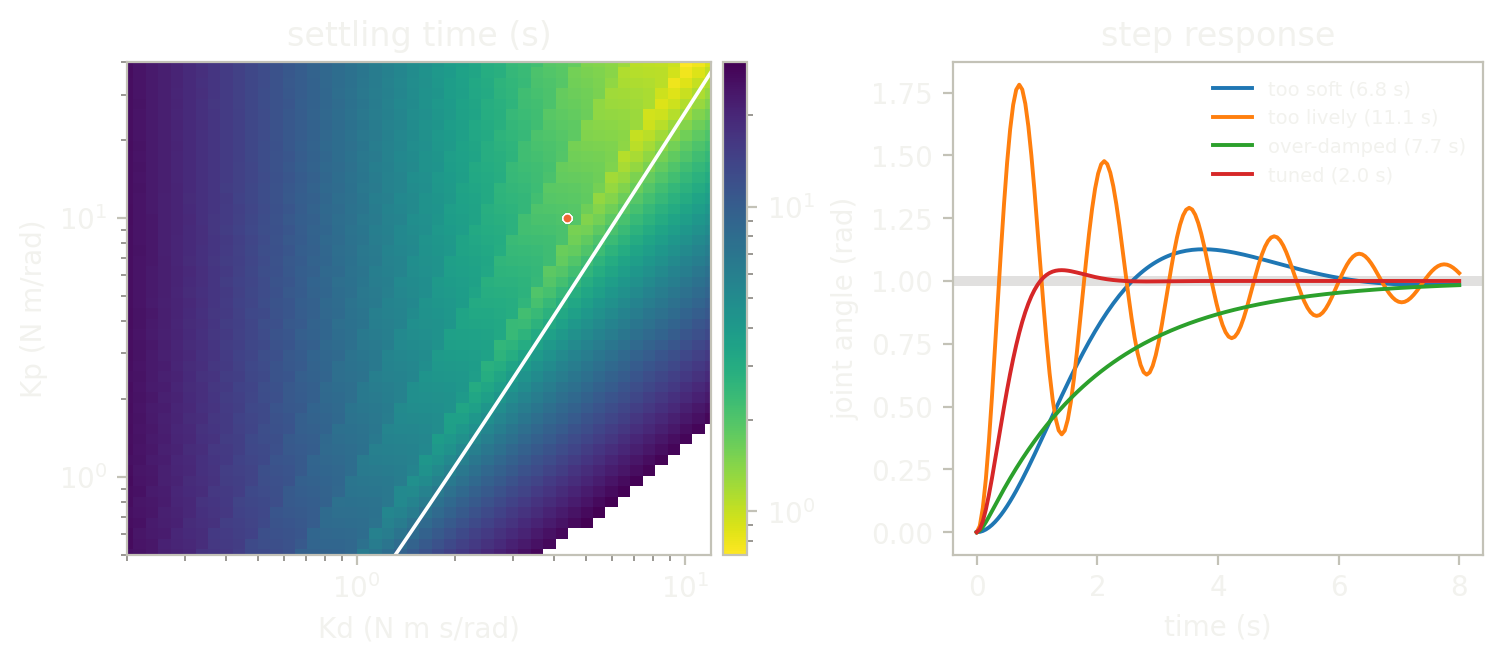

In [9]:
import matplotlib.pyplot as plt

N_STEPS = 200


@Plant
def position(kp, kd, inertia, friction, t_obs: Scalar, theta: Mutable[Scalar]):
    c = kd + friction
    dt = t_obs / N_STEPS
    e = 1.0
    v = 0.0
    for _ in range(N_STEPS):
        k1e = -v
        k1v = (kp * e - c * v) / inertia
        k2e = -(v + 0.5 * dt * k1v)
        k2v = (kp * (e + 0.5 * dt * k1e) - c * (v + 0.5 * dt * k1v)) / inertia
        k3e = -(v + 0.5 * dt * k2v)
        k3v = (kp * (e + 0.5 * dt * k2e) - c * (v + 0.5 * dt * k2v)) / inertia
        k4e = -(v + dt * k3v)
        k4v = (kp * (e + dt * k3e) - c * (v + dt * k3v)) / inertia
        e = e + dt * (k1e + 2.0 * k2e + 2.0 * k3e + k4e) / 6.0
        v = v + dt * (k1v + 2.0 * k2v + 2.0 * k3v + k4v) / 6.0
    theta = 1.0 - e


shown = {"too soft": (1.0, 1.0), "too lively": (20.0, 0.6), "over-damped": (6.0, 12.0), "tuned": (float(opt_p), float(opt_d))}
times = np.linspace(0.0, 8.0, 160)
pos = position(kp=np.repeat([k for k, _ in shown.values()], len(times)), kd=np.repeat([d for _, d in shown.values()], len(times)),
               inertia=INERTIA, friction=FRICTION, t_obs=np.tile(times, len(shown)))
curves = np.asarray(pos).reshape(len(shown), len(times))


def exact_position(t, kp, c, J=INERTIA):
    sq = np.sqrt(np.complex128(c**2 / J**2 - 4 * kp / J))
    l1, l2 = (-c / J + sq) / 2, (-c / J - sq) / 2
    return 1.0 - ((l2 * np.exp(l1 * t) - l1 * np.exp(l2 * t)) / (l2 - l1)).real


exact_curves = np.stack([exact_position(times, k, d + FRICTION) for k, d in shown.values()])
gap_pos = np.abs(curves - exact_curves).max()
assert gap_pos < 1e-4, gap_pos
print(f"the four step responses against the exact solution: worst gap {gap_pos:.1e}")
t_exact = {name: float(exact_settle(np.array(k), np.array(d))) for name, (k, d) in shown.items()}

fig, (left, right) = plt.subplots(1, 2, figsize=(7.4, 3.2), constrained_layout=True, gridspec_kw={"width_ratios": [1.1, 1]})
mesh = left.pcolormesh(kds, kps, np.where(t_settle < HORIZON, t_settle, np.nan), norm=plt.matplotlib.colors.LogNorm(), cmap="viridis_r", shading="auto")
kd_line = 2 * np.sqrt(kps * INERTIA) - FRICTION
left.plot(kd_line, kps, color="white", lw=1.3)
left.plot(best[1], best[0], "o", ms=3.2, color="#eb6834", mec="white", mew=0.4)
left.set_xscale("log"); left.set_yscale("log"); left.set_xlim(kds[0], kds[-1]); left.set_ylim(kps[0], kps[-1])
left.set_xlabel("Kd (N m s/rad)"); left.set_ylabel("Kp (N m/rad)"); left.set_title("settling time (s)")
fig.colorbar(mesh, ax=left, pad=0.02)
for (name, (k, d)), curve in zip(shown.items(), curves):
    right.plot(times, curve, lw=1.4, label=f"{name} ({t_exact[name]:.1f} s)")
right.axhspan(0.98, 1.02, color="#898781", alpha=0.25, lw=0)
right.set_xlabel("time (s)"); right.set_ylabel("joint angle (rad)"); right.set_title("step response"); right.legend(frameon=False, fontsize=7)
show(fig, f"Two panels. Left: settling time of {t_settle.size} gain pairs on log axes, fastest ({t_settle.min():.1f} seconds) at the stiffest corner and slow where the gains are too soft or over-damped, with the critical-damping curve drawn; the forty tuned gain pairs all end at Kp {opt_p:.1f}, Kd {opt_d:.1f}, which is a damping ratio of {zeta_opt:.2f}. Right: step responses of four gain pairs against time, with the 2 percent band shaded; the tuned pair settles in {t_exact['tuned']:.1f} seconds.")

## A bigger map, when a GPU is there

This cell runs only when a GPU is present; on a CPU runtime it prints that and does nothing. The same kernel runs through `eagle.deploy` on device arrays, with the two gain axes expanded to the whole grid. The map must agree with the host map above to rounding.

In [10]:
if gpu_available():
    kp_full = xp.asarray(np.broadcast_to(kps[:, None], (N_GAINS, N_GAINS)).copy())
    kd_full = xp.asarray(np.broadcast_to(kds[None, :], (N_GAINS, N_GAINS)).copy())
    got = eagle.deploy(settle).run(kp=kp_full, kd=kd_full, inertia=INERTIA, friction=FRICTION, band=BAND, gain_p=N_GAINS)
    assert on_device(got["t_settle"]), "the result is a device array: the kernel ran on the GPU"
    diff = np.abs(to_numpy(got["t_settle"]) - t_settle).max()
    assert diff < 1e-9, diff
    print(f"{N_GAINS * N_GAINS} gain pairs on the GPU: settling times agree with the host map, worst gap {diff:.1e} s")
else:
    print("no GPU here; the map stays at", N_GAINS, "x", N_GAINS)

2304 gain pairs on the GPU: settling times agree with the host map, worst gap 0.0e+00 s


## The animation

The forty gain pairs as they descend the cost, drawn on the settling-time map: every dot is one lane of the reverse-mode launch, and they converge to the same point from all over the map. The helper that writes a looping GIF for a light page and one for a dark page is shared with the other domain pages.

In [11]:
from anim import frame_of, write_anim
from themed_figure import DARK, LIGHT

path = np.exp(np.stack(trail))                                  # (iteration, 2, start): Kp, Kd
shown_iter = sorted(set(np.unique(np.round(np.geomspace(1, len(path) - 1, 40)).astype(int))) | {0})
shown_log = np.log10(np.where(t_settle < HORIZON, t_settle, np.nan))


def render(theme, k):
    pal = LIGHT if theme == "light" else DARK
    fig = plt.figure(figsize=(5.0, 3.2), facecolor=pal["bg"])
    ax = fig.add_axes([0.13, 0.17, 0.83, 0.76], facecolor=pal["bg"])
    ax.pcolormesh(kds, kps, shown_log, cmap="viridis_r", shading="auto", alpha=0.9)
    ax.plot(kd_line, kps, color="white", lw=1.0)
    lo = max(0, k - 12)
    for s in range(n_start):
        ax.plot(path[lo:k + 1, 1, s], path[lo:k + 1, 0, s], lw=0.5, color="#eb6834", alpha=0.6)
    ax.plot(path[k, 1], path[k, 0], "o", ms=3.0, color="#eb6834", mec="white", mew=0.4)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(kds[0], kds[-1]); ax.set_ylim(kps[0], kps[-1])
    ax.set_xlabel("Kd (N m s/rad)", color=pal["sub"], fontsize=8); ax.set_ylabel("Kp (N m/rad)", color=pal["sub"], fontsize=8)
    ax.tick_params(colors=pal["sub"], labelsize=7)
    for sp in ax.spines.values():
        sp.set_color(pal["rule"])
    ax.text(0.03, 0.06, f"step {k}", transform=ax.transAxes, fontsize=8, color="white")
    return frame_of(fig, pal["bg"])


frames_at = shown_iter + [len(path) - 1] * 8
sizes = {}
for theme in ("light", "dark"):
    sizes.update(write_anim([render(theme, k) for k in frames_at], f"gain_tuning_{theme}", fps=8))
for name, size in sizes.items():
    print(name, f"{size / 1e3:.0f} kB")
assert max(sizes.values()) < 1.5e6

gain_tuning_light.gif 358 kB
gain_tuning_dark.gif 320 kB


```{image} ../../_static/anim/gain_tuning_light.gif
:class: only-light
:alt: Forty orange dots start scattered over a map of settling time against the two gains, and as the gradient steps proceed they run across the map and gather at the minimum of the cost, on the underdamped side of the white critical-damping curve (damping ratio 0.71).
```
```{image} ../../_static/anim/gain_tuning_dark.gif
:class: only-dark
:alt: Forty orange dots start scattered over a map of settling time against the two gains, and as the gradient steps proceed they run across the map and gather at the minimum of the cost, on the underdamped side of the white critical-damping curve (damping ratio 0.71).
```

## What just happened

- `Plant` named the two gains and the plant once; `settle` is the response in those names, one lane per gain pair on a `Grid`, with the gain axes given as `kps[:, None]` and `kds[None, :]` and broadcast, not expanded.
- Each lane left its loop when its energy crossed the 2% threshold. The settling times agreed with the exact response of the loop, the error fell at second order as `dt` halved, and the overshoot matched the closed form; the energy balance held to the scheme's error (2e-7 of E(0)).
- `vjp` gave the gradient of a cost with respect to both gains for forty gain pairs in one launch. It matched a finite difference of the same integration to rounding and the Lyapunov closed form within the scheme's error.
- Steepest descent in log-gains took all forty starts to the closed-form minimum, at the linear-quadratic stiffness `Kp = 1 / sqrt(w)`.

## Try this

Change the cost weight `W_EFFORT` and watch the tuned gains move toward a softer loop, then check the new minimum against `closed_cost`. Or add a second plant parameter, say a larger inertia, and see the map's fast region shift along the diagonal.

## Next

[Epidemiology](20_epidemiology) fits a model to counts with the same reverse-mode pattern. [Molecular dynamics](22_molecular_dynamics) takes forces from the gradient of an energy.